In [5]:
import pandas as pd
import os

path = r"C:\Users\HP\Downloads\exports"

try:
    # On ajoute quotechar='"' et on force le moteur Python pour mieux gérer les erreurs
    df_orders = pd.read_csv(os.path.join(path, "orders.csv"), sep=None, engine='python', on_bad_lines='warn')
    df_products = pd.read_csv(os.path.join(path, "products.csv"), sep=None, engine='python', on_bad_lines='warn')
    df_customers = pd.read_csv(os.path.join(path, "customers.csv"), sep=None, engine='python', on_bad_lines='warn')
    df_details = pd.read_csv(os.path.join(path, "orderdetails.csv"), sep=None, engine='python', on_bad_lines='warn')
    
    print("\n✅ CONNEXION RÉUSSIE !")
    print(f"-> Produits : {len(df_products)} lignes chargées.")
    display(df_products.head(3))

except Exception as e:
    print(f"\n❌ ERREUR : {e}")


✅ CONNEXION RÉUSSIE !
-> Produits : 102 lignes chargées.


C:\Users\HP\AppData\Local\Temp\ipykernel_2740\146793229.py:9: ParserWarning: Skipping line 12: ',' expected after '"'

  df_products = pd.read_csv(os.path.join(path, "products.csv"), sep=None, engine='python', on_bad_lines='warn')
C:\Users\HP\AppData\Local\Temp\ipykernel_2740\146793229.py:9: ParserWarning: Skipping line 16: ',' expected after '"'

  df_products = pd.read_csv(os.path.join(path, "products.csv"), sep=None, engine='python', on_bad_lines='warn')
C:\Users\HP\AppData\Local\Temp\ipykernel_2740\146793229.py:9: ParserWarning: Skipping line 46: ',' expected after '"'

  df_products = pd.read_csv(os.path.join(path, "products.csv"), sep=None, engine='python', on_bad_lines='warn')
C:\Users\HP\AppData\Local\Temp\ipykernel_2740\146793229.py:9: ParserWarning: Skipping line 58: ',' expected after '"'

  df_products = pd.read_csv(os.path.join(path, "products.csv"), sep=None, engine='python', on_bad_lines='warn')
C:\Users\HP\AppData\Local\Temp\ipykernel_2740\146793229.py:9: ParserWarning:

,productCode,productName,productLine,productScale,productVendor,productDescription,quantityInStock,buyPrice,MSRP
0,S10_1678,1969 Harley Davidson Ultimate Chopper,Motorcycles,1:10,Min Lin Diecast,"This replica features working kickstand, front...",7933,48.81,95.70
1,S10_1949,1952 Alpine Renault 1300,Classic Cars,1:10,Classic Metal Creations,Turnable front wheels; steering function; deta...,7305,98.58,214.30
2,S10_2016,1996 Moto Guzzi 1100i,Motorcycles,1:10,Highway 66 Mini Classics,"Official Moto Guzzi logos and insignias, saddl...",6625,68.99,118.94


📊 Génération des analyses...


C:\Users\HP\AppData\Local\Temp\ipykernel_2740\47112936.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_prod, x='quantityOrdered', y='productName', palette='magma')


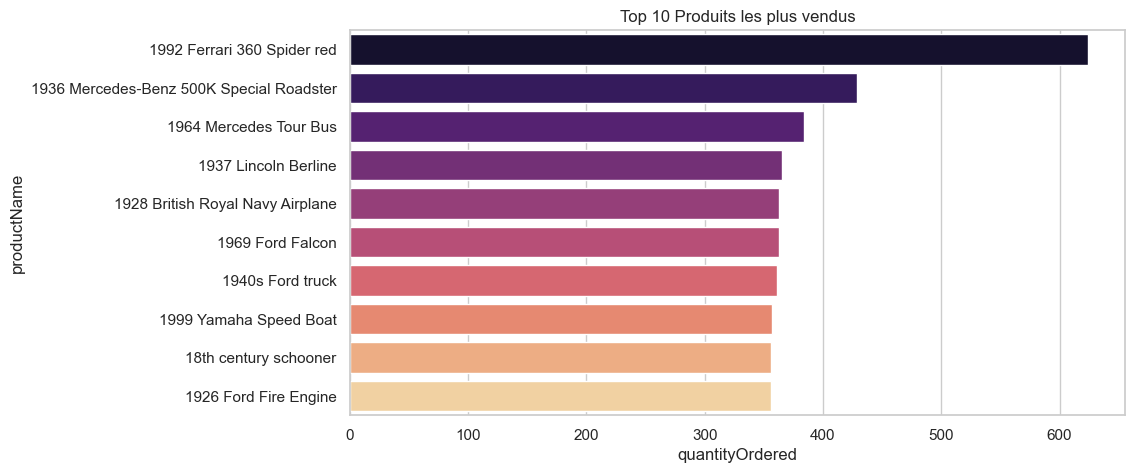

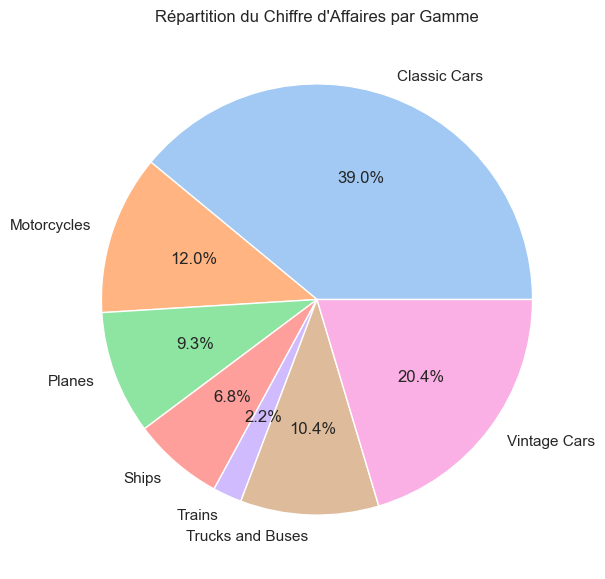

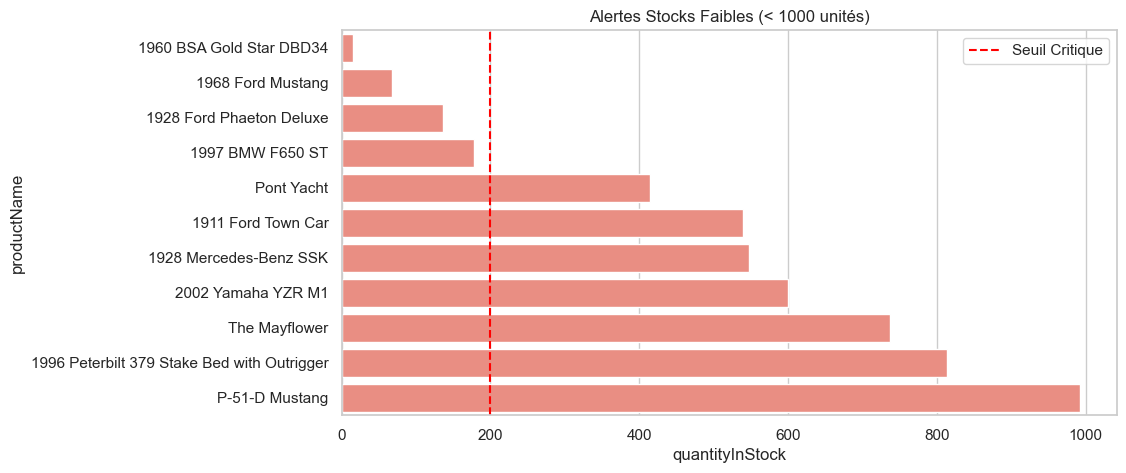

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Préparation des calculs
df_details['total_price'] = df_details['quantityOrdered'] * df_details['priceEach']
df_master = pd.merge(df_details, df_orders, on='orderNumber')
df_master = pd.merge(df_master, df_customers, on='customerNumber')
df_master = pd.merge(df_master, df_products, on='productCode')

sns.set_theme(style="whitegrid")
print("📊 Génération des analyses...")

# --- (1) TOP 10 PRODUITS ---
plt.figure(figsize=(10, 5))
top_prod = df_master.groupby('productName')['quantityOrdered'].sum().sort_values(ascending=False).head(10).reset_index()
sns.barplot(data=top_prod, x='quantityOrdered', y='productName', palette='magma')
plt.title("Top 10 Produits les plus vendus")
plt.show()

# --- (2) RÉPARTITION PAR GAMME ---
plt.figure(figsize=(7, 7))
ca_gamme = df_master.groupby('productLine')['total_price'].sum().reset_index()
plt.pie(ca_gamme['total_price'], labels=ca_gamme['productLine'], autopct='%1.1f%%', colors=sns.color_palette('pastel'))
plt.title("Répartition du Chiffre d'Affaires par Gamme")
plt.show()

# --- (3) ÉTAT DES STOCKS ---
plt.figure(figsize=(10, 5))
st = df_products[df_products['quantityInStock'] < 1000].sort_values('quantityInStock').head(12)
sns.barplot(data=st, x='quantityInStock', y='productName', color='salmon')
plt.axvline(200, color='red', linestyle='--', label='Seuil Critique')
plt.title("Alertes Stocks Faibles (< 1000 unités)")
plt.legend()
plt.show()

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# On utilise tes fichiers chargés depuis Downloads
df_details['total_price'] = df_details['quantityOrdered'] * df_details['priceEach']
df_master = pd.merge(df_details, df_orders, on='orderNumber')
df_master = pd.merge(df_master, df_customers, on='customerNumber')
df_master = pd.merge(df_master, df_products, on='productCode')

sns.set_theme(style="whitegrid")

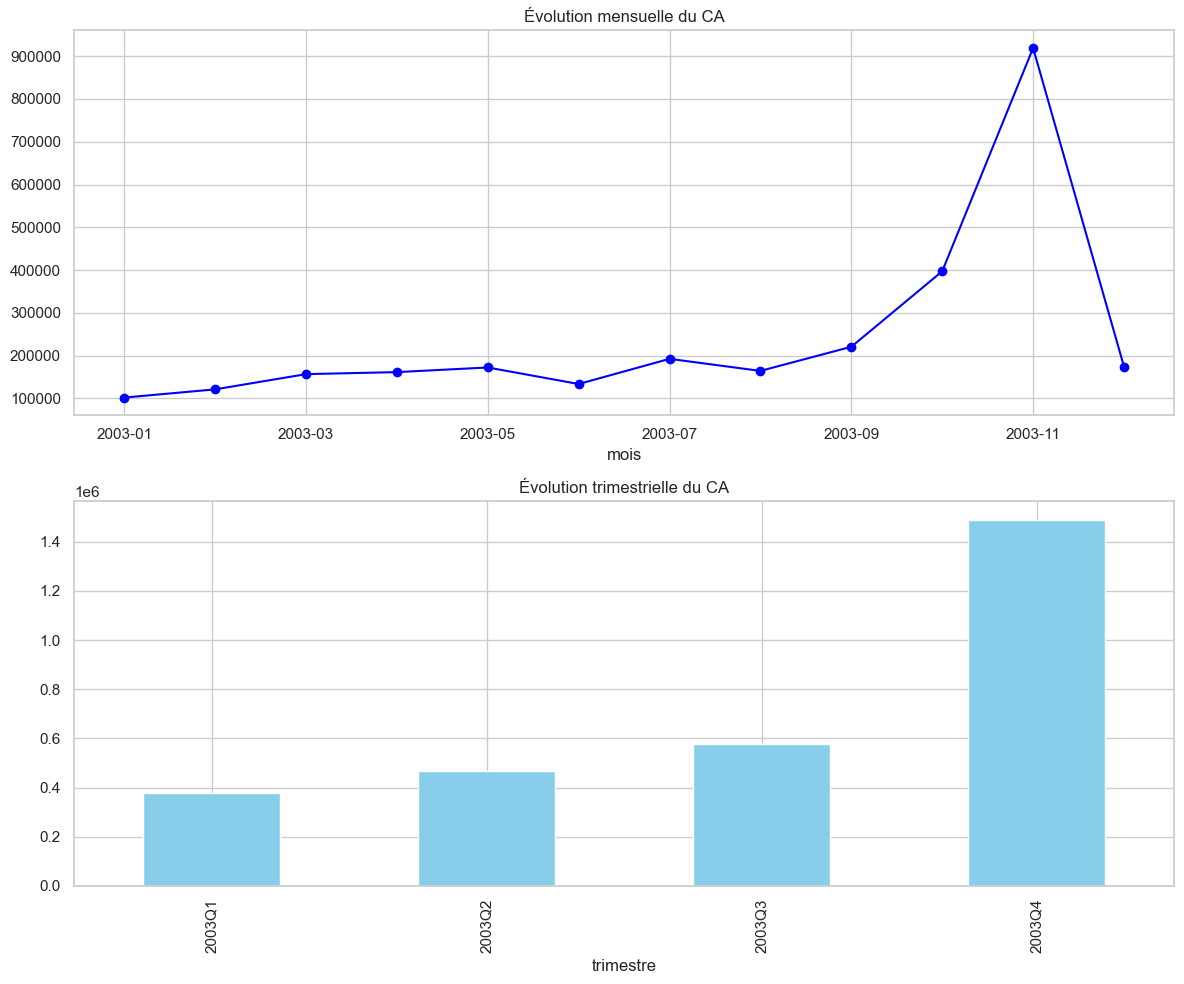

In [16]:
df_master['orderDate'] = pd.to_datetime(df_master['orderDate'])
df_master['mois'] = df_master['orderDate'].dt.to_period('M').astype(str)
df_master['trimestre'] = df_master['orderDate'].dt.to_period('Q').astype(str)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# Par mois
ca_mensuel = df_master.groupby('mois')['total_price'].sum()
ca_mensuel.plot(kind='line', marker='o', ax=ax1, color='blue')
ax1.set_title("Évolution mensuelle du CA")

# Par trimestre
ca_trim = df_master.groupby('trimestre')['total_price'].sum()
ca_trim.plot(kind='bar', ax=ax2, color='skyblue')
ax2.set_title("Évolution trimestrielle du CA")

plt.tight_layout()
plt.savefig(r"C:\Users\HP\Documents\classicmodels-analysis\visualizations\01_evolution_temporelle.png")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_2740\2611210054.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ca_pays.values, y=ca_pays.index, palette='viridis')


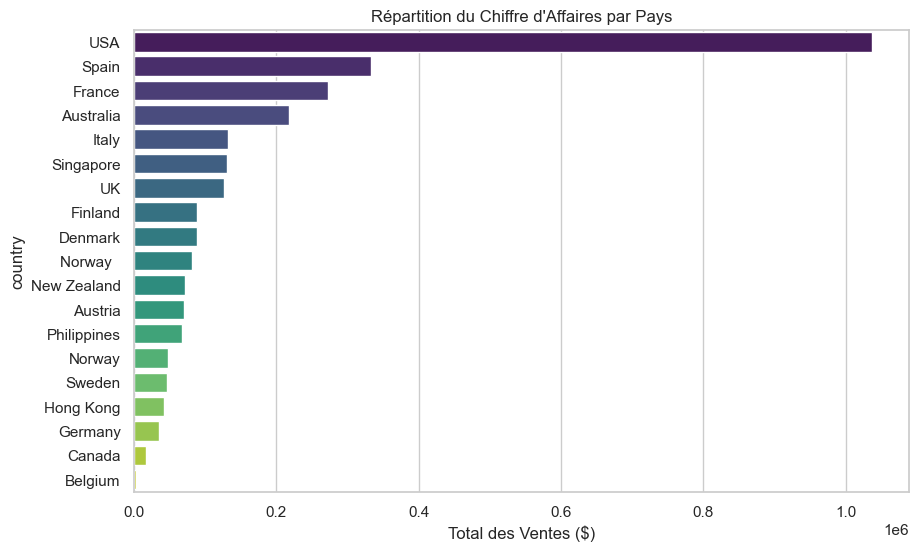

In [17]:
plt.figure(figsize=(10, 6))
ca_pays = df_master.groupby('country')['total_price'].sum().sort_values(ascending=False)
sns.barplot(x=ca_pays.values, y=ca_pays.index, palette='viridis')
plt.title("Répartition du Chiffre d'Affaires par Pays")
plt.xlabel("Total des Ventes ($)")
# À ajouter avant plt.show()
plt.savefig(r"C:\Users\HP\Documents\classicmodels-analysis\visualizations\02_repartition_geo.png")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_2740\3757723020.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ca_gamme.index, y=ca_gamme.values, palette='magma')


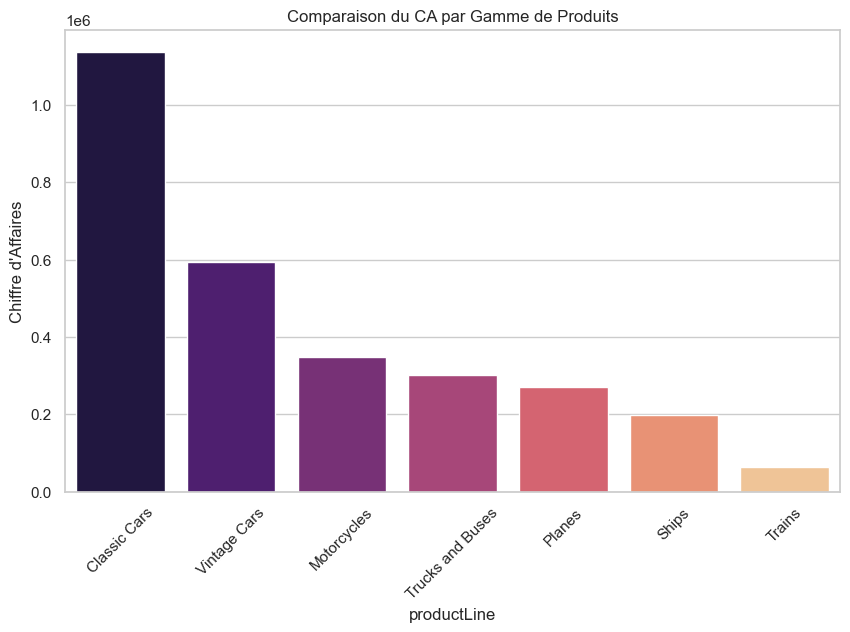

In [18]:
plt.figure(figsize=(10, 6))
ca_gamme = df_master.groupby('productLine')['total_price'].sum().sort_values(ascending=False)
sns.barplot(x=ca_gamme.index, y=ca_gamme.values, palette='magma')
plt.title("Comparaison du CA par Gamme de Produits")
plt.ylabel("Chiffre d'Affaires")
plt.xticks(rotation=45)
# À ajouter avant plt.show()
plt.savefig(r"C:\Users\HP\Documents\classicmodels-analysis\visualizations\03_ventes_gammes.png")
plt.show()

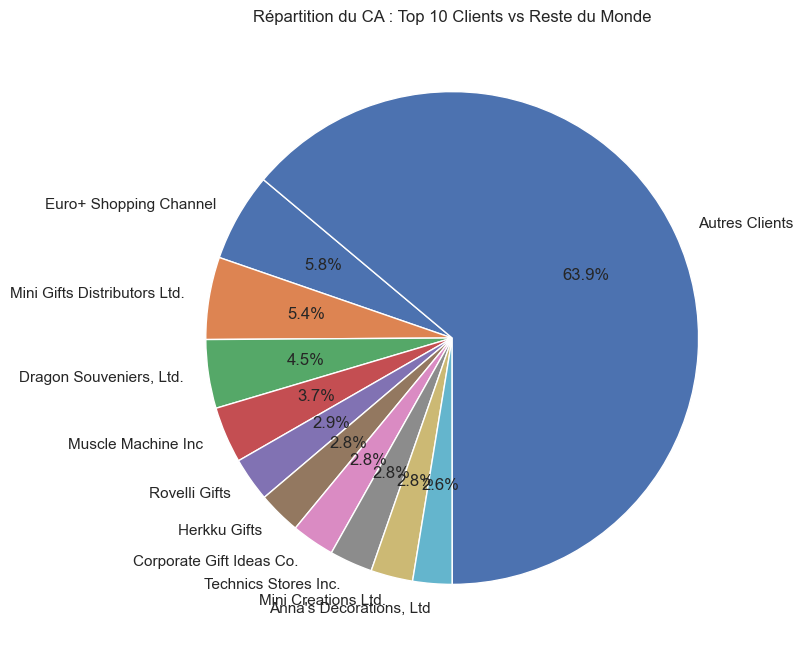

In [20]:
# Calcul du CA par client
ca_par_client = df_master.groupby('customerName')['total_price'].sum().sort_values(ascending=False)

# On prend les 10 premiers, et on somme tout le reste dans "Autres"
top_10 = ca_par_client.head(10)
autres = pd.Series({'Autres Clients': ca_par_client.iloc[10:].sum()})
final_repartition = pd.concat([top_10, autres])

plt.figure(figsize=(8, 8))
plt.pie(final_repartition, labels=final_repartition.index, autopct='%1.1f%%', startangle=140)
plt.title("Répartition du CA : Top 10 Clients vs Reste du Monde")
# À ajouter avant plt.show()
plt.savefig(r"C:\Users\HP\Documents\classicmodels-analysis\visualizations\06_top_clients.png")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_2740\1599511165.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_produits, x='quantityOrdered', y='productName', palette='Blues_r')


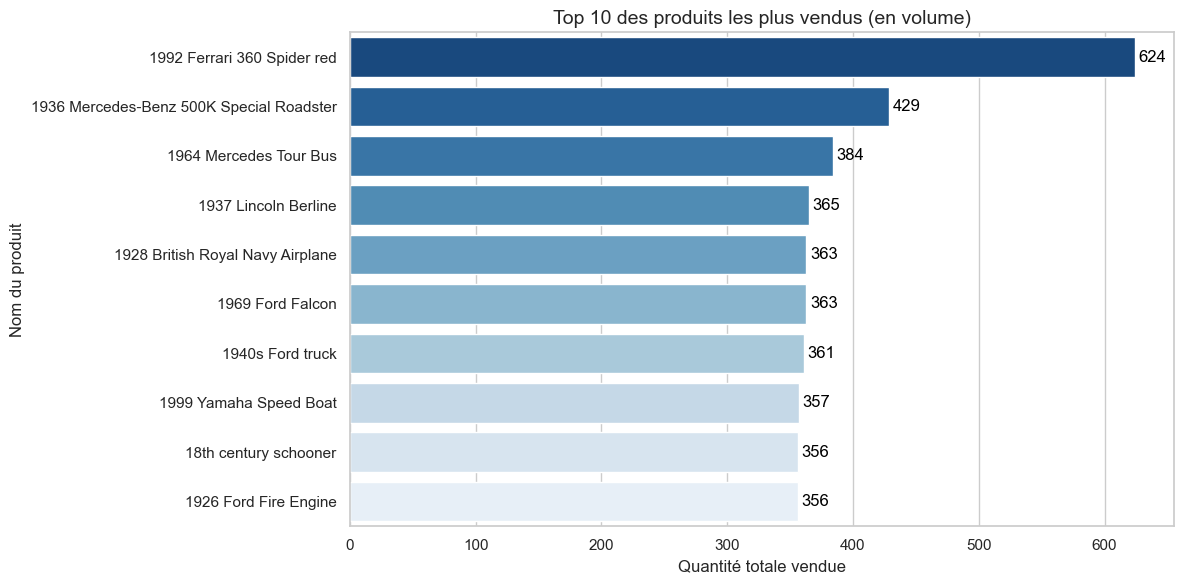

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# On regroupe par nom de produit et on somme les quantités commandées
top_produits = df_master.groupby('productName')['quantityOrdered'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=top_produits, x='quantityOrdered', y='productName', palette='Blues_r')

plt.title("Top 10 des produits les plus vendus (en volume)", fontsize=14)
plt.xlabel("Quantité totale vendue", fontsize=12)
plt.ylabel("Nom du produit", fontsize=12)

# On ajoute les chiffres au bout des barres pour plus de clarté
for i, v in enumerate(top_produits['quantityOrdered']):
    plt.text(v + 3, i, str(int(v)), color='black', va='center')

plt.tight_layout()
plt.savefig(r"C:\Users\HP\Documents\classicmodels-analysis\visualizations\04_top_produits.png")
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_2740\2079210458.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=stocks_faibles, x='quantityInStock', y='productName', palette=colors)


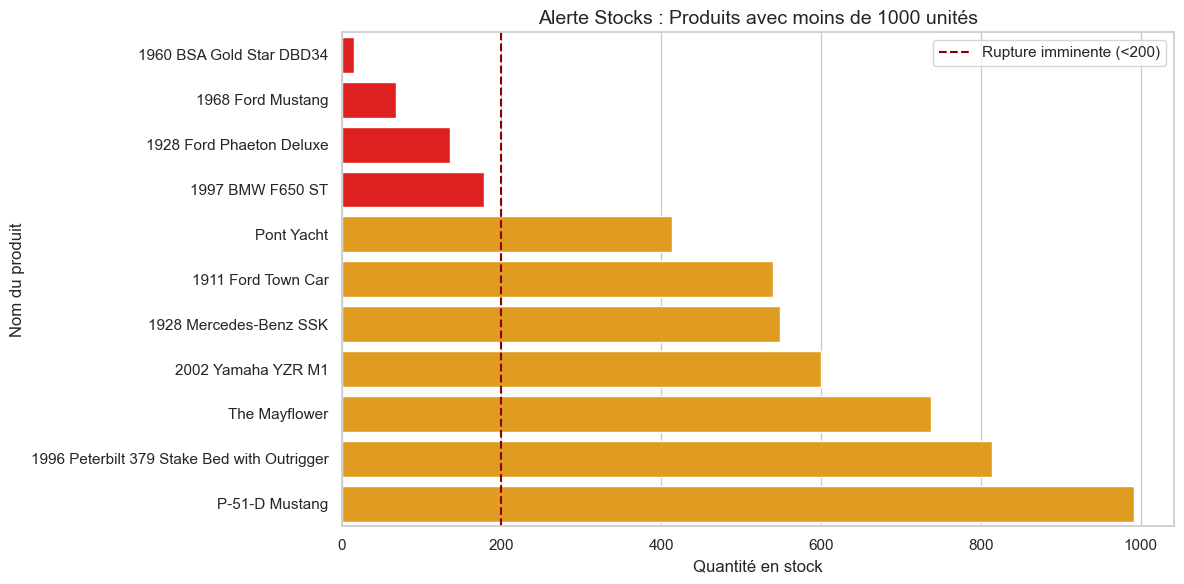

In [14]:
# On définit un seuil critique (ex: moins de 500 unités en stock)
seuil_alerte = 1000

# On filtre les produits sous ce seuil
stocks_faibles = df_products[df_products['quantityInStock'] < seuil_alerte].sort_values('quantityInStock').head(15)

plt.figure(figsize=(12, 6))
# Couleur rouge pour montrer l'urgence
colors = ['red' if x < 200 else 'orange' for x in stocks_faibles['quantityInStock']]

sns.barplot(data=stocks_faibles, x='quantityInStock', y='productName', palette=colors)

plt.axvline(x=200, color='darkred', linestyle='--', label='Rupture imminente (<200)')
plt.title(f"Alerte Stocks : Produits avec moins de {seuil_alerte} unités", fontsize=14)
plt.xlabel("Quantité en stock", fontsize=12)
plt.ylabel("Nom du produit", fontsize=12)
plt.legend()

plt.tight_layout()
plt.savefig(r"C:\Users\HP\Documents\classicmodels-analysis\visualizations\05_etat_stocks.png")
plt.show()